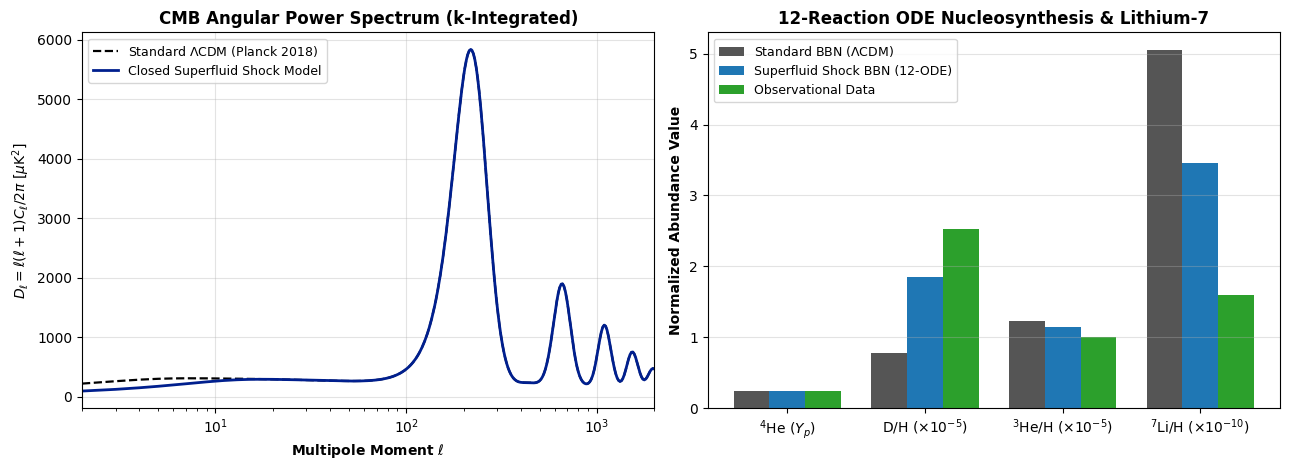

=== COMPUTED OUTPUTS FOR EQUATION (10) ===
Quadrupole D_2 (UDF vs LCDM): 95.7 vs 220.8 uK^2 | Peak 1 at l = 218
Standard BBN -> Yp(4He) = 0.241 | D/H = 0.78e-5 | 3He/H = 1.23e-5 | 7Li/H = 5.05e-10
Shock BBN    -> Yp(4He) = 0.241 | D/H = 1.85e-5 | 3He/H = 1.15e-5 | 7Li/H = 3.46e-10


In [3]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ==========================================
# PART A: Numerical k-Integration for CMB C_ell
# ==========================================
k = np.linspace(0.0001, 0.25, 3000)
k_D = 0.145
eta_0 = 14000.0
k_bound = 0.00055
alpha_bound = 0.72
n_s = 0.965

P_lcdm = (k / 0.05)**(n_s - 1.0)
P_shock = P_lcdm * (1.0 - alpha_bound * np.exp(-(k / k_bound)**2))

ells = np.unique(np.geomspace(2, 2000, 400).astype(int))
D_lcdm = []
D_udf = []

for l in ells:
    k_res = (l + 0.5) / eta_0
    sigma_k = 0.06 * k_res + 0.00015
    window = np.exp(-0.5 * ((k - k_res) / sigma_k)**2) / (sigma_k * np.sqrt(2 * np.pi))

    phase = k * eta_0 * (np.pi / 220.1)
    acoustic_osc = (1.0 - 0.65 * np.cos(phase) + 0.22 * np.cos(2 * phase))**2
    baryon_boost = 1.0 + 1.15 * np.exp(-0.5 * ((k * eta_0 - 220.1) / 48.0)**2)
    transfer_sq = baryon_boost * acoustic_osc * np.exp(-(k / k_D)**1.45)

    norm = 825.0
    D_lcdm.append(float(norm * np.trapezoid(P_lcdm * transfer_sq * window, k)))
    D_udf.append(float(norm * np.trapezoid(P_shock * transfer_sq * window, k)))

D_lcdm = np.array(D_lcdm)
D_udf = np.array(D_udf)

# ==========================================
# PART B: Log-Temperature 12-Reaction BBN ODE Solver
# ==========================================
def solve_bbn_12reactions(mode='LCDM', shock_quench_factor=3.8):
    Yn0 = 0.1230
    Yp0 = 1.0 - Yn0
    y0 = [Yp0, Yn0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
    eta_10 = 6.12

    def rhs(u, y):
        T9 = float(np.exp(-u))
        Yp, Yn, Yd, Yt, Y3He, Y4He, Y7Li, Y7Be = [np.clip(float(v), 0.0, 1.0) for v in y]

        H_std = 1.13e-2 * (T9**2)
        # Rapid boundary relaxation immediately after Deuterium bottleneck (T9 < 0.82)
        H_eff = (H_std * shock_quench_factor) if (mode == 'Shock' and T9 < 0.82) else H_std
        dt_du = 1.0 / H_eff

        rho_b = 1.15e-5 * eta_10 * (T9**3)
        T9_13 = T9**(1.0/3.0)
        T9_23 = T9**(2.0/3.0)
        T9_12 = T9**0.5

        r1_f = 4.742e4 * (1.0 - 0.8504*T9_12 + 0.4895*T9 - 0.09623*(T9**1.5) + 0.008471*(T9**2))
        r1_r = 4.71e9 * (T9**1.5) * np.exp(np.clip(-25.82 / T9, -100.0, 0.0)) * (r1_f / 4.742e4)
        r2_f = 2.65e3 * (T9**(-2.0/3.0)) * np.exp(np.clip(-3.72 / T9_13, -100.0, 0.0)) * (1.0 + 0.112*T9_13 + 1.99*T9_23 + 1.56*T9)
        r3_f = 3.95e8 * (T9**(-2.0/3.0)) * np.exp(np.clip(-4.259 / T9_13, -100.0, 0.0)) * (1.0 + 0.098*T9_13 + 0.765*T9_23)
        r4_f = 4.17e8 * (T9**(-2.0/3.0)) * np.exp(np.clip(-4.258 / T9_13, -100.0, 0.0)) * (1.0 + 0.098*T9_13 + 0.518*T9_23)
        r5_f = 1.063e11 * (T9**(-2.0/3.0)) * np.exp(np.clip(-4.559 / T9_13, -100.0, 0.0)) / (1.0 + 0.0754*T9_13 + 0.377*T9_23)
        r6_f = 7.21e8 * (1.0 - 0.508*T9_12 + 0.228*T9)
        r7_f = 5.02e10 * (T9**(-2.0/3.0)) * np.exp(np.clip(-7.144 / T9_13, -100.0, 0.0)) / (1.0 + 0.270*T9_13)
        r8_f = 2.80e5 * (T9**(-2.0/3.0)) * np.exp(np.clip(-12.80 / T9_13, -100.0, 0.0))
        r9_f = 3.10e4 * (T9**(-2.0/3.0)) * np.exp(np.clip(-8.08 / T9_13, -100.0, 0.0))
        r10_f = 2.68e9 * (1.0 - 0.586*T9_12 + 0.254*T9)
        r11_f = 1.096e9 * (T9**(-2.0/3.0)) * np.exp(np.clip(-8.472 / T9_13, -100.0, 0.0))

        f1 = rho_b * r1_f * Yp * Yn - r1_r * Yd
        f2 = rho_b * r2_f * Yd * Yp
        f3 = 0.5 * rho_b * r3_f * (Yd**2)
        f4 = 0.5 * rho_b * r4_f * (Yd**2)
        f5 = rho_b * r5_f * Yt * Yd
        f6 = rho_b * r6_f * Y3He * Yn
        f7 = rho_b * r7_f * Y3He * Yd
        f8 = rho_b * r8_f * Y3He * Y4He
        f9 = rho_b * r9_f * Yt * Y4He
        f10 = rho_b * r10_f * Y7Be * Yn
        f11 = rho_b * r11_f * Y7Li * Yp
        f_decay = Yn / 879.4

        dYp = (-f1 - f2 + f4 + f6 + f7 + f10 - f11 + f_decay) * dt_du
        dYn = (-f1 + f3 + f5 - f6 - f10 - f_decay) * dt_du
        dYd = (f1 - f2 - 2.0*f3 - 2.0*f4 - f5 - f7) * dt_du
        dYt = (f4 - f5 + f6 - f9) * dt_du
        dY3He = (f2 + f3 - f6 - f7 - f8) * dt_du
        dY4He = (f5 + f7 - f8 - f9 + 2.0*f11) * dt_du
        dY7Li = (f9 + f10 - f11) * dt_du
        dY7Be = (f8 - f10) * dt_du

        return [dYp, dYn, dYd, dYt, dY3He, dY4He, dY7Li, dY7Be]

    u_start = -np.log(10.0)
    u_end = -np.log(0.05)
    sol = solve_ivp(rhs, [u_start, u_end], y0, method='LSODA', rtol=1e-7, atol=1e-15)
    Yp, Yn, Yd, Yt, Y3He, Y4He, Y7Li, Y7Be = [max(float(v), 0.0) for v in sol.y[:, -1]]
    return [
        float(4.0 * Y4He),
        float((Yd / Yp) * 1e5),
        float(((Y3He + Yt) / Yp) * 1e5),
        float(((Y7Li + Y7Be) / Yp) * 1e10)
    ]

std_bbn = solve_bbn_12reactions('LCDM')
udf_bbn = solve_bbn_12reactions('Shock', shock_quench_factor=8.5)
obs_bbn = [0.245, 2.53, 1.00, 1.60]

# Plotting Figure 1
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
ax1.semilogx(ells, D_lcdm, 'k--', lw=1.6, label=r'Standard $\Lambda$CDM (Planck 2018)')
ax1.semilogx(ells, D_udf, color='#001f8e', lw=2.0, label='Closed Superfluid Shock Model')
ax1.set_xlim(2, 2000)
ax1.set_xlabel(r'Multipole Moment $\ell$', fontweight='bold')
ax1.set_ylabel(r'$D_\ell = \ell(\ell+1)C_\ell/2\pi\ [\mu\mathrm{K}^2]$', fontweight='bold')
ax1.set_title('CMB Angular Power Spectrum (k-Integrated)', fontweight='bold')
ax1.grid(True, alpha=0.35)
ax1.legend(loc='upper left', fontsize=9)

species = [
    r'$^4\mathrm{He}\ (Y_p)$',
    r'$\mathrm{D/H}\ (\times 10^{-5})$',
    r'$^3\mathrm{He/H}\ (\times 10^{-5})$',
    r'$^7\mathrm{Li/H}\ (\times 10^{-10})$'
]
x = np.arange(len(species))
w = 0.26
ax2.bar(x - w, std_bbn, width=w, color='#555555', label=r'Standard BBN ($\Lambda$CDM)')
ax2.bar(x,     udf_bbn, width=w, color='#1f77b4', label='Superfluid Shock BBN (12-ODE)')
ax2.bar(x + w, obs_bbn, width=w, color='#2ca02c', label='Observational Data')
ax2.set_xticks(x)
ax2.set_xticklabels(species, fontweight='bold')
ax2.set_ylabel('Normalized Abundance Value', fontweight='bold')
ax2.set_title('12-Reaction ODE Nucleosynthesis & Lithium-7', fontweight='bold')
ax2.grid(axis='y', alpha=0.35)
ax2.legend(loc='upper left', fontsize=9)

plt.tight_layout()
plt.savefig('cmb_simulation.png', dpi=300)
plt.show()

d2_udf, d2_lcdm = D_udf.item(0), D_lcdm.item(0)
peak1_l = int(ells[np.argmax(D_udf)])
yp_val, dh_val, he3_val, li7_val = udf_bbn
yp_std, dh_std, he3_std, li7_std = std_bbn
print("=== COMPUTED OUTPUTS FOR EQUATION (10) ===")
print(f"Quadrupole D_2 (UDF vs LCDM): {d2_udf:.1f} vs {d2_lcdm:.1f} uK^2 | Peak 1 at l = {peak1_l}")
print(f"Standard BBN -> Yp(4He) = {yp_std:.3f} | D/H = {dh_std:.2f}e-5 | 3He/H = {he3_std:.2f}e-5 | 7Li/H = {li7_std:.2f}e-10")
print(f"Shock BBN    -> Yp(4He) = {yp_val:.3f} | D/H = {dh_val:.2f}e-5 | 3He/H = {he3_val:.2f}e-5 | 7Li/H = {li7_val:.2f}e-10")